## IC Analysis
Trying to match the pdf given in the mesa2ic process, and see if lscale reproduces it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import glob
import pandas as pd
import os

### Loading in MESA profile

In [2]:
all_files = sorted(glob.glob('profile1.data'))
all_files

['profile1.data']

In [3]:
# MESA_headers = 
with open(all_files[0], "r") as f:
    f.readline()
    f.readline()
    f.readline()
    f.readline()
    f.readline()
    MESA_headers = f.readline().split()
MESA_headers

['zone',
 'mass',
 'logR',
 'logT',
 'logRho',
 'logP',
 'x_mass_fraction_H',
 'y_mass_fraction_He',
 'z_mass_fraction_metals',
 'logdq',
 'dq_ratio',
 'q',
 'radius',
 'velocity',
 'v_div_r',
 'pressure_scale_height',
 'mmid',
 'logxq',
 'dr',
 'temperature',
 'entropy',
 'pressure',
 'logPgas',
 'pgas_div_ptotal',
 'eta',
 'mu',
 'grada',
 'free_e',
 'csound',
 'v_div_csound',
 'eps_grav',
 'eps_nuc',
 'non_nuc_neu',
 'pp',
 'cno',
 'tri_alpha',
 'c_alpha',
 'n_alpha',
 'o_alpha',
 'ne_alpha',
 'na_alpha',
 'mg_alpha',
 'si_alpha',
 's_alpha',
 'ar_alpha',
 'ca_alpha',
 'ti_alpha',
 'cr_alpha',
 'fe_co_ni',
 'c12_c12',
 'c12_o16',
 'o16_o16',
 'pnhe4',
 'photo',
 'ni56_co56',
 'co56_fe56',
 'other',
 'abar',
 'ye',
 'h1',
 'he3',
 'he4',
 'c12',
 'n14',
 'o16',
 'ne20',
 'mg24',
 'log_opacity',
 'luminosity',
 'logL',
 'total_energy',
 'mlt_mixing_length',
 'mlt_mixing_type',
 'log_conv_vel',
 'gradT',
 'gradr',
 'grad_temperature',
 'grad_density',
 'gradL',
 'sch_stable',
 'ledoux_

In [4]:
mesa_df = pd.DataFrame(np.genfromtxt(all_files[0],skip_header=6),columns=MESA_headers)
mesa_df.set_index('zone')

,mass,logR,logT,logRho,logP,x_mass_fraction_H,y_mass_fraction_He,z_mass_fraction_metals,logdq,dq_ratio,...,am_log_D_SH,am_log_D_SSI,am_log_D_ES,am_log_D_GSF,am_log_D_ST,am_log_nu_ST,dynamo_log_B_r,dynamo_log_B_phi,brunt_N2,brunt_B
zone,,,,,,,,,,,,,,,,,,,,,
1.0,2.000000e+01,0.760963,4.540705,-8.994687,3.914323,0.700000,0.280000,0.020000,-12.698970,1.000000,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,1.084063e-05,0.000000e+00
2.0,2.000000e+01,0.760959,4.541396,-8.989985,3.918589,0.700000,0.280000,0.020000,-12.522879,0.666667,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,1.072829e-05,0.000000e+00
3.0,2.000000e+01,0.760953,4.542111,-8.985200,3.922963,0.700000,0.280000,0.020000,-12.662040,1.377721,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,1.039462e-05,0.000000e+00
4.0,2.000000e+01,0.760948,4.542711,-8.981240,3.926608,0.700000,0.280000,0.020000,-12.662040,1.000000,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,1.015686e-05,0.000000e+00
5.0,2.000000e+01,0.760944,4.543312,-8.977338,3.930224,0.700000,0.280000,0.020000,-12.662040,1.000000,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,9.922954e-06,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4662.0,6.250523e-06,-1.910127,7.553384,0.675444,16.430078,0.698646,0.280791,0.020562,-6.806144,2.000000,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-2.586113e-16,1.826107e-09
4663.0,3.125262e-06,-2.010473,7.553387,0.675452,16.430090,0.698646,0.280791,0.020562,-7.107174,2.000000,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-1.629735e-16,1.630580e-09
4664.0,1.562631e-06,-2.110817,7.553389,0.675457,16.430097,0.698646,0.280791,0.020562,-7.408204,2.000000,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-1.039009e-16,-6.327222e-09


### Loading in lscale struc file

In [6]:
absolute_path = "/z2/users/cj517/lscaledir_20M/ic_analysis/hemisphere/struc*"
PATTERN = os.path.relpath(absolute_path)

all_files = sorted(glob.glob(PATTERN))
all_files

['../../../../../z2/users/cj517/lscaledir_20M/ic_analysis/hemisphere/struc.cont000000001']

In [7]:
spec_file = all_files[0]

In [8]:
with open(spec_file, "r") as f:
    f.readline()
    f.readline()
    print(f.readline())

index                            radius                           vel_rms                          crossing_time_vel                crossing_time_hp                 press_height                     e_int_spec                       nabla                            nabla_adiab                      pressure                         temperature                      entropy                          entropy_calc                     e_kin                            shell_mass                       density                          flux_enthalpy                    flux_e_kin                       flux_rad                         flux_diff_scalar                 vel_1_rms                        vel_2_rms                        vel_3_rms                        vel_1                            vel_2                            vel_3                            theta_1                          u_phi_average_1                  theta_2                          u_phi_average_2                  theta_3   

In [9]:
top_headers = ['time', 'e_kin_tot', 'temp_tot', 'convective_time_hp', 'convective_time_vel_rms', 'convective_time_vel_1_rms', 'convective_time_hp_vel_rms']
time, e_kin_tot, temp_tot, convective_time_hp, convective_time_vel_rms, convective_time_vel_1_rms, convective_time_hp_vel_rms = [1.999982E+07, 9.576E+38, 2.714E+06, 1.274E+06, 2.445E+06, 6.477E+06, 3.251E+06]
headers = ['index', 'radius', 'vel_rms', 'crossing_time_vel', 'crossing_time_hp', 'press_height', 'e_int_spec', 'nabla', 'nabla_adiab', 'pressure', 'temperature', 'entropy', 'entropy_calc', 'e_kin', 'shell_mass', 'density', 'flux_enthalpy', 'flux_e_kin', 'flux_rad', 'flux_diff_scalar', 'vel_1_rms', 'vel_2_rms', 'vel_3_rms', 'vel_1', 'vel_2', 'vel_3', 'theta_1', 'u_phi_average_1', 'theta_2', 'u_phi_average_2', 'theta_3', 'u_phi_average_3', 'theta_4', 'u_phi_average_4', 'theta_5', 'u_phi_average_5', 'theta_6', 'u_phi_average_6', 'theta_7', 'u_phi_average_7', 'theta_8', 'u_phi_average_8', 'theta_9', 'u_phi_average_9', 'theta_10', 'u_phi_average_10', 'theta_11', 'u_phi_average_11', 'angular_momentum', 'scalar', 'flux_mass', 'nabla_mu_equiv', 'flux_heat_instant', 'flux_heat_init', 'flux_heat_ref_prof', 'flux_heat_ref_field', 'brunt_vaissala', 'temperature_std', 'temperature_skew', 'temperature_kurt', 'temperature_rms', 'density_std', 'density_skew', 'density_kurt', 'density_rms', 'temperature_fluct', 'temperature_up_fluct', 'temperature_down_fluct', 'vel_1_correlation', 'buoyancy_work', 'vel_1_std', 'vel_1_skew', 'vel_1_kurt', 'vel_1_rms', 'temperature_gradient', 'thermal_conductivity', 'strain_dev_1_1_squared', 'strain_dev_2_2_squared', 'strain_dev_3_3_squared', 'strain_dev_1_2_squared', 'strain_dev_1_3_squared', 'strain_dev_2_3_squared']

In [10]:
r_sun = 6.9570000000000000E+010
r_tot = 5.7671763407229273 * r_sun
# r_bot = 0.4 * r_tot
# r_top = 0.9 * r_tot
# Nr = 570
# Ntheta = 360
# Nphi = 720
# dr_grid = (r_top - r_bot) / Nr
r_env_init = 0.2836686568328816 * r_tot

In [11]:
df = pd.DataFrame(np.genfromtxt(spec_file,skip_header=3),columns=headers)
df = df.set_index('index')
df

,radius,vel_rms,crossing_time_vel,crossing_time_hp,press_height,e_int_spec,nabla,nabla_adiab,pressure,temperature,...,vel_1_kurt,vel_1_rms,temperature_gradient,thermal_conductivity,strain_dev_1_1_squared,strain_dev_2_2_squared,strain_dev_3_3_squared,strain_dev_1_2_squared,strain_dev_1_3_squared,strain_dev_2_3_squared
index,,,,,,,,,,,,,,,,,,,,,
1.0,5.223932e+10,0.0,inf,inf,8.309699e+10,8.795925e+15,0.308412,0.308481,1.962934e+16,3.259412e+07,...,NaN,0.0,0.000121,8.320583e+18,0.0,0.0,0.0,0.0,0.0,0.0
2.0,5.248037e+10,0.0,inf,inf,8.284216e+10,8.786289e+15,0.308391,0.308513,1.957243e+16,3.256496e+07,...,NaN,0.0,0.000121,8.312623e+18,0.0,0.0,0.0,0.0,0.0,0.0
3.0,5.272141e+10,0.0,inf,inf,8.247178e+10,8.776620e+15,0.308422,0.308545,1.951544e+16,3.253568e+07,...,NaN,0.0,0.000122,8.304630e+18,0.0,0.0,0.0,0.0,0.0,0.0
4.0,5.296246e+10,0.0,inf,inf,8.210478e+10,8.766917e+15,0.308454,0.308577,1.945835e+16,3.250630e+07,...,NaN,0.0,0.000122,8.296606e+18,0.0,0.0,0.0,0.0,0.0,0.0
5.0,5.320351e+10,0.0,inf,inf,8.174113e+10,8.757181e+15,0.308486,0.308609,1.940118e+16,3.247681e+07,...,NaN,0.0,0.000123,8.288549e+18,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
508.0,1.744501e+11,0.0,inf,inf,2.679019e+10,3.098885e+15,0.259088,0.334326,8.820017e+14,1.301326e+07,...,NaN,0.0,0.000126,3.609141e+18,0.0,0.0,0.0,0.0,0.0,0.0
509.0,1.746912e+11,0.0,inf,inf,2.676537e+10,3.091536e+15,0.258886,0.334340,8.740978e+14,1.298296e+07,...,NaN,0.0,0.000126,3.607605e+18,0.0,0.0,0.0,0.0,0.0,0.0
510.0,1.749322e+11,0.0,inf,inf,2.674067e+10,3.084208e+15,0.258682,0.334355,8.662574e+14,1.295272e+07,...,NaN,0.0,0.000125,3.606100e+18,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
np.array([df['radius'].min(), df['radius'].max()]) / r_sun

array([0.75088861, 2.52140724])

In [13]:
r_env_init / r_sun

1.635967166291246

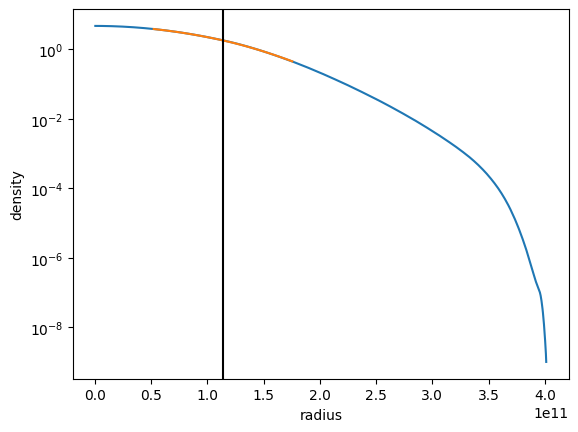

In [14]:
plt.semilogy(r_sun*(10**mesa_df['logR']),10**mesa_df['logRho'])
plt.semilogy(df['radius'],df['density'])
# plt.ylim([10**4,10**17])
plt.ylabel('density')
plt.xlabel('radius')
plt.axvline(r_env_init,c='k')
plt.savefig('density.png')

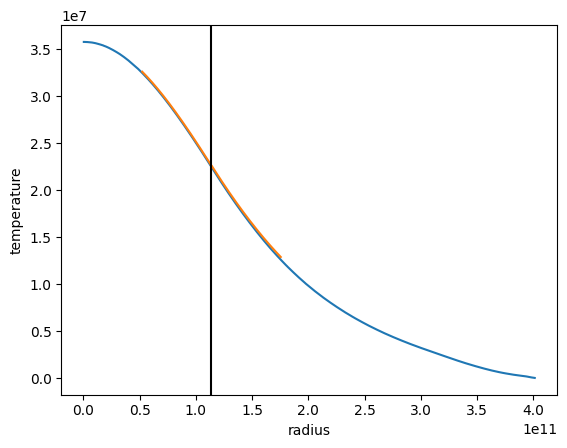

In [15]:
plt.plot(r_sun*(10**mesa_df['logR']),10**mesa_df['logT'])
plt.plot(df['radius'],df['temperature'])
# plt.ylim([10**4,10**17])
plt.ylabel('temperature')
plt.xlabel('radius')
plt.axvline(r_env_init,c='k')
plt.savefig('temperature.png')

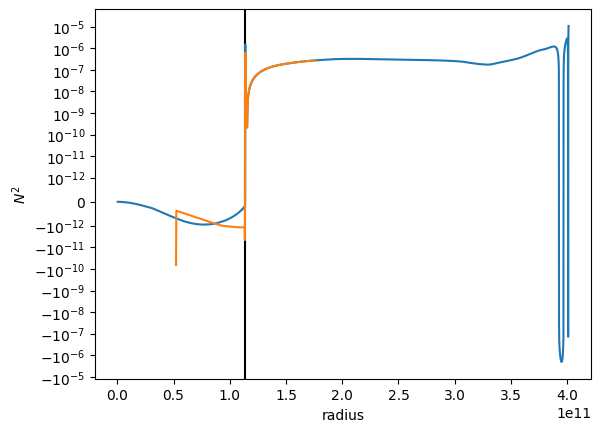

In [16]:
plt.axvline(r_env_init,c='k')
plt.plot(r_sun*(10**mesa_df['logR']),mesa_df['brunt_N2'])
plt.plot(df['radius'],df['brunt_vaissala'])
# plt.ylim([10**4,10**17])
plt.yscale('symlog',linthresh=1e-12)
plt.ylabel(r'$N^2$')
plt.xlabel('radius')
plt.savefig('N2.png')